# Model Training — Good/Poor Sleep Classifier

Trains and evaluates two classifiers on the Kaggle Sleep Health & Lifestyle dataset.
Output of this notebook: `models/model.pkl` (best model + its scaler, ready for inference)
and `models/metrics.json` (performance report).

**Steps:**

1. Load data, create binary target
2. 80/20 stratified train/test split
3. Pipeline with `StandardScaler` + classifier (scaler is saved with the model so inference doesn't have to redo it)
4. Baseline: Logistic Regression (5-fold CV)
5. Main: Random Forest with GridSearchCV over `n_estimators`, `max_depth`, `min_samples_split`, `class_weight`
6. Compare both on CV scores
7. Pick the winner and evaluate on the held-out test set
8. Confusion matrix, ROC curve, feature importances
9. Save model + metrics

**Pre-requisite:** `data/kaggle/Sleep_health_and_lifestyle_dataset.csv` must exist (same file used in notebook 01).

## 1. Setup

In [1]:
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score, precision_score, recall_score,
    confusion_matrix, roc_curve, classification_report
)

RANDOM_STATE = 42
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "kaggle" / "Sleep_health_and_lifestyle_dataset.csv"
MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(exist_ok=True)

print("Data:", DATA_PATH)
print("Models output:", MODELS_DIR)

Data: c:\Users\rodri\Documents\sleep-behavior-tracker\data\kaggle\Sleep_health_and_lifestyle_dataset.csv
Models output: c:\Users\rodri\Documents\sleep-behavior-tracker\models


In [2]:
df = pd.read_csv(DATA_PATH)

FEATURES = [
    "Sleep Duration",
    "Heart Rate",
    "Physical Activity Level",
    "Stress Level",
    "Daily Steps",
]
TARGET_RAW = "Quality of Sleep"

df["sleep_label"] = (df[TARGET_RAW] >= 7).astype(int)

X = df[FEATURES].copy()
y = df["sleep_label"].copy()

print(f"X: {X.shape}, y: {y.shape}")
print(f"Class balance: {y.value_counts(normalize=True).round(3).to_dict()}")

X: (374, 5), y: (374,)
Class balance: {1: 0.687, 0: 0.313}


## 2. Train/test split

80/20 stratified so both splits keep the ~69/31 class ratio.
Test set is **held out**. Not touched again until the final evaluation at step 7.
All model selection happens via 5-fold CV on the training set.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print(f"Train: {len(X_train)} rows  (good={y_train.sum()}, poor={(y_train==0).sum()})")
print(f"Test:  {len(X_test)} rows  (good={y_test.sum()}, poor={(y_test==0).sum()})")

Train: 299 rows  (good=205, poor=94)
Test:  75 rows  (good=52, poor=23)


## 3. Pipeline: StandardScaler + classifier

Wrapping the scaler and the classifier in a `Pipeline` has two concrete benefits:

1. **No data leakage in CV.** Each fold fits its own scaler on its training portion only.
2. **Inference is one-step.** When we load `model.pkl` later and call `.predict(X_new)`,
   the same scaler fitted on Kaggle gets applied automatically. We never have to
   remember to rescale manually.

For the Random Forest, scaling is technically unnecessary (trees are scale-invariant),
but keeping the same pipeline shape for both models makes the code simpler and doesn't
hurt.

In [4]:
def make_pipeline(classifier):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("clf", classifier),
    ])

# Shared CV splitter so both models are evaluated on the exact same folds
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Metrics tracked for every model
SCORING = {
    "accuracy": "accuracy",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "precision": "precision",
    "recall": "recall",
}

## 4. Baseline: Logistic Regression

Simple linear baseline. If a tuned Random Forest can't beat this clearly, the extra
complexity isn't justified.

In [5]:
lr_pipeline = make_pipeline(
    LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
)

lr_cv = cross_validate(
    lr_pipeline, X_train, y_train,
    cv=cv, scoring=SCORING, return_train_score=False
)

lr_summary = {metric: float(lr_cv[f"test_{metric}"].mean()) for metric in SCORING}
lr_summary_std = {metric: float(lr_cv[f"test_{metric}"].std()) for metric in SCORING}

print("Logistic Regression — 5-fold CV (mean ± std):")
for m in SCORING:
    print(f"  {m:10s}: {lr_summary[m]:.3f} ± {lr_summary_std[m]:.3f}")

Logistic Regression — 5-fold CV (mean ± std):
  accuracy  : 0.977 ± 0.017
  f1        : 0.983 ± 0.013
  roc_auc   : 0.999 ± 0.001
  precision : 0.995 ± 0.010
  recall    : 0.971 ± 0.024


## 5. Random Forest with GridSearchCV

Hyperparameters searched:

- `n_estimators`: number of trees (100 vs 300)
- `max_depth`: tree depth cap (None = unlimited, or 5 / 10)
- `min_samples_split`: minimum samples to split a node (2 or 5)
- `class_weight`: `None` or `"balanced"`. Tested because the EDA showed moderate imbalance

Total: 2 × 3 × 2 × 2 = 24 combinations × 5 folds = 120 fits. Fast on this dataset size.

**Scoring metric for grid search:** F1 (balances precision and recall under class imbalance).

In [6]:
rf_pipeline = make_pipeline(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
)

param_grid = {
    "clf__n_estimators": [100, 300],
    "clf__max_depth": [None, 5, 10],
    "clf__min_samples_split": [2, 5],
    "clf__class_weight": [None, "balanced"],
}

rf_search = GridSearchCV(
    rf_pipeline,
    param_grid=param_grid,
    scoring=SCORING,
    refit="f1",
    cv=cv,
    n_jobs=-1,
    return_train_score=False,
)

rf_search.fit(X_train, y_train)

print("Best params:", rf_search.best_params_)
print()
best_idx = rf_search.best_index_
cv_results = rf_search.cv_results_
rf_summary = {m: float(cv_results[f"mean_test_{m}"][best_idx]) for m in SCORING}
rf_summary_std = {m: float(cv_results[f"std_test_{m}"][best_idx]) for m in SCORING}

print("Best Random Forest — 5-fold CV (mean ± std):")
for m in SCORING:
    print(f"  {m:10s}: {rf_summary[m]:.3f} ± {rf_summary_std[m]:.3f}")

Best params: {'clf__class_weight': None, 'clf__max_depth': None, 'clf__min_samples_split': 5, 'clf__n_estimators': 300}

Best Random Forest — 5-fold CV (mean ± std):
  accuracy  : 0.990 ± 0.008
  f1        : 0.993 ± 0.006
  roc_auc   : 0.999 ± 0.001
  precision : 0.995 ± 0.010
  recall    : 0.990 ± 0.012


## 6. Side-by-side comparison

In [7]:
comparison = pd.DataFrame({
    "LogReg (mean)":    lr_summary,
    "LogReg (std)":     lr_summary_std,
    "RandomForest (mean)": rf_summary,
    "RandomForest (std)":  rf_summary_std,
}).round(3)
comparison

,LogReg (mean),LogReg (std),RandomForest (mean),RandomForest (std)
accuracy,0.977,0.017,0.990,0.008
f1,0.983,0.013,0.993,0.006
roc_auc,0.999,0.001,0.999,0.001
precision,0.995,0.010,0.995,0.010
recall,0.971,0.024,0.990,0.012


In [ ]:
#Pick the winner based on F1 (the primary metric per the EDA findings)
if rf_summary["f1"] >= lr_summary["f1"]:
    winner_name = "RandomForest"
    winner_model = rf_search.best_estimator_
    winner_cv = rf_summary
    winner_cv_std = rf_summary_std
else:
    winner_name = "LogisticRegression"
    #Refit the LR pipeline on the full training set
    winner_model = lr_pipeline.fit(X_train, y_train)
    winner_cv = lr_summary
    winner_cv_std = lr_summary_std

print(f"Selected model: {winner_name} (CV F1 = {winner_cv['f1']:.3f})")

Selected model: RandomForest (CV F1 = 0.993)


## 7. Final evaluation on the held-out test set

This is the honest number. The test set was never seen during model selection.

In [9]:
y_pred = winner_model.predict(X_test)
y_proba = winner_model.predict_proba(X_test)[:, 1]

test_metrics = {
    "accuracy":  float(accuracy_score(y_test, y_pred)),
    "f1":        float(f1_score(y_test, y_pred)),
    "roc_auc":   float(roc_auc_score(y_test, y_proba)),
    "precision": float(precision_score(y_test, y_pred)),
    "recall":    float(recall_score(y_test, y_pred)),
}

print(f"{winner_name} — held-out test set ({len(y_test)} rows):")
for m, v in test_metrics.items():
    print(f"  {m:10s}: {v:.3f}")
print()
print("Classification report:")
print(classification_report(y_test, y_pred, target_names=["poor (0)", "good (1)"]))

RandomForest — held-out test set (75 rows):
  accuracy  : 0.973
  f1        : 0.981
  roc_auc   : 0.998
  precision : 0.963
  recall    : 1.000

Classification report:
              precision    recall  f1-score   support

    poor (0)       1.00      0.91      0.95        23
    good (1)       0.96      1.00      0.98        52

    accuracy                           0.97        75
   macro avg       0.98      0.96      0.97        75
weighted avg       0.97      0.97      0.97        75



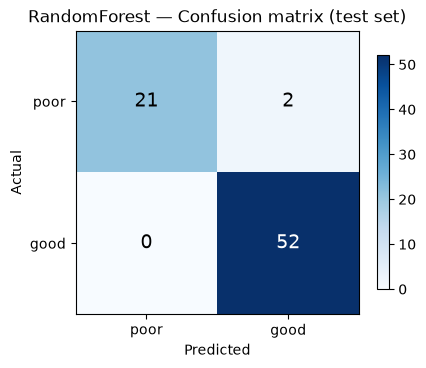

In [ ]:
#Confusion matrix
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(4.5, 4))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(["poor", "good"])
ax.set_yticklabels(["poor", "good"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title(f"{winner_name} — Confusion matrix (test set)")
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=14)
plt.colorbar(im, ax=ax, shrink=0.7)
plt.tight_layout()
plt.show()

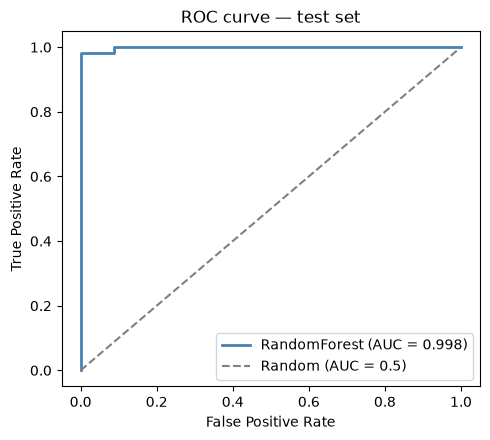

In [11]:
#ROC curve
fpr, tpr, _ = roc_curve(y_test, y_proba)
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.plot(fpr, tpr, label=f"{winner_name} (AUC = {test_metrics['roc_auc']:.3f})",
        color="steelblue", linewidth=2)
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random (AUC = 0.5)")
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("ROC curve — test set")
ax.legend()
plt.tight_layout()
plt.show()

## 8. Feature importances

For Random Forest: how much each feature contributed to splits across all trees.
Expect **Daily Steps** to be near zero (confirming the EDA: correlation with target was 0.01).

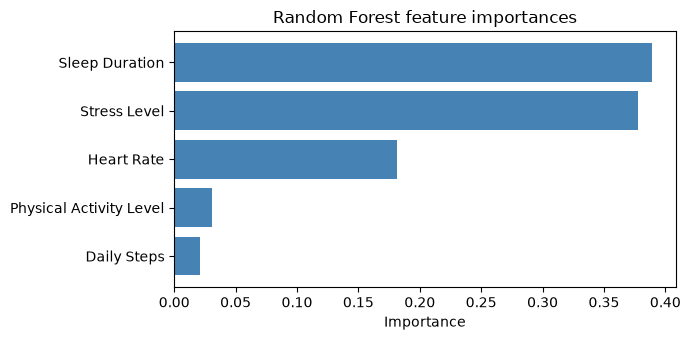

                feature  importance
         Sleep Duration    0.389133
           Stress Level    0.377340
             Heart Rate    0.181334
Physical Activity Level    0.031014
            Daily Steps    0.021179


In [12]:
if winner_name == "RandomForest":
    importances = winner_model.named_steps["clf"].feature_importances_
    fi_df = pd.DataFrame({
        "feature": FEATURES,
        "importance": importances,
    }).sort_values("importance", ascending=True)

    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.barh(fi_df["feature"], fi_df["importance"], color="steelblue")
    ax.set_xlabel("Importance")
    ax.set_title("Random Forest feature importances")
    plt.tight_layout()
    plt.show()
    print(fi_df.sort_values("importance", ascending=False).to_string(index=False))
else:
    coefs = winner_model.named_steps["clf"].coef_[0]
    coef_df = pd.DataFrame({"feature": FEATURES, "coef (standardized)": coefs})
    print("Logistic Regression coefficients (on standardized features):")
    print(coef_df.sort_values("coef (standardized)", key=abs, ascending=False)
          .to_string(index=False))

## 9. Save model and metrics

- `models/model.pkl`. The fitted pipeline (scaler + classifier), ready to call `.predict()` on new data
- `models/metrics.json`. All CV + test metrics, model name, chosen hyperparameters

In [13]:
model_path = MODELS_DIR / "model.pkl"
metrics_path = MODELS_DIR / "metrics.json"

joblib.dump(winner_model, model_path)

report = {
    "winner": winner_name,
    "features": FEATURES,
    "random_state": RANDOM_STATE,
    "train_size": int(len(X_train)),
    "test_size": int(len(X_test)),
    "class_balance_train": y_train.value_counts(normalize=True).round(3).to_dict(),
    "cv_scores": {
        "logistic_regression": {"mean": lr_summary, "std": lr_summary_std},
        "random_forest":       {"mean": rf_summary, "std": rf_summary_std},
    },
    "random_forest_best_params": {k: (v if not isinstance(v, type(None)) else None)
                                   for k, v in rf_search.best_params_.items()},
    "test_metrics": test_metrics,
}

with open(metrics_path, "w") as f:
    json.dump(report, f, indent=2, default=str)

print(f"Saved model to:   {model_path}")
print(f"Saved metrics to: {metrics_path}")

Saved model to:   c:\Users\rodri\Documents\sleep-behavior-tracker\models\model.pkl
Saved metrics to: c:\Users\rodri\Documents\sleep-behavior-tracker\models\metrics.json


## 10. Sanity check — can we load and predict?

Quick end-to-end check: reload the saved model and run it on one row of training data.
This is exactly what `src/predict.py` will do later with Samsung Health data.

In [14]:
loaded = joblib.load(model_path)
sample = X_train.iloc[[0]]
print("Sample input:")
print(sample)
print()
print(f"Predicted label: {loaded.predict(sample)[0]}  (1=good, 0=poor)")
print(f"Predicted probability of 'good': {loaded.predict_proba(sample)[0, 1]:.3f}")
print(f"Actual label: {y_train.iloc[0]}")

Sample input:
     Sleep Duration  Heart Rate  Physical Activity Level  Stress Level  \
193             6.5          72                       45             7   

     Daily Steps  
193         6000  

Predicted label: 0  (1=good, 0=poor)
Predicted probability of 'good': 0.140
Actual label: 0
